# Module 1: Introduction to Redis for AI & LLM Caching

## Welcome to the Course!

In this course, you will learn how to use **Redis** as a caching layer to make your AI applications:

- **Faster** — Get instant responses instead of waiting 2-10 seconds for every API call
- **Cheaper** — Avoid paying for the same LLM response twice
- **Smarter** — Give AI agents persistent memory across conversations

### Course Modules:
| Module | Topic |
|--------|-------|
| **Module 1** | Introduction to Redis + Setup (this one) |
| **Module 2** | Exact Match LLM Caching |
| **Module 3** | Semantic Caching with Embeddings |
| **Module 4** | AI Agent Conversation Memory |
| **Module 5** | Rate Limiting & API Cost Control |
| **Module 6** | RAG with Cached Embeddings |
| **Module 7** | Final Gradio Demo App |

---

> **No prior Redis experience needed.** We start from absolute zero.

## 1. What is Redis?

**Redis** stands for **RE**mote **DI**ctionary **S**erver.

### Who Uses Redis?
- **Twitter** stores user timelines in Redis
- **GitHub** uses Redis for caching
- **Stack Overflow** caches question/answer content in Redis
- **OpenAI** uses Redis for semantic caching of API responses

---

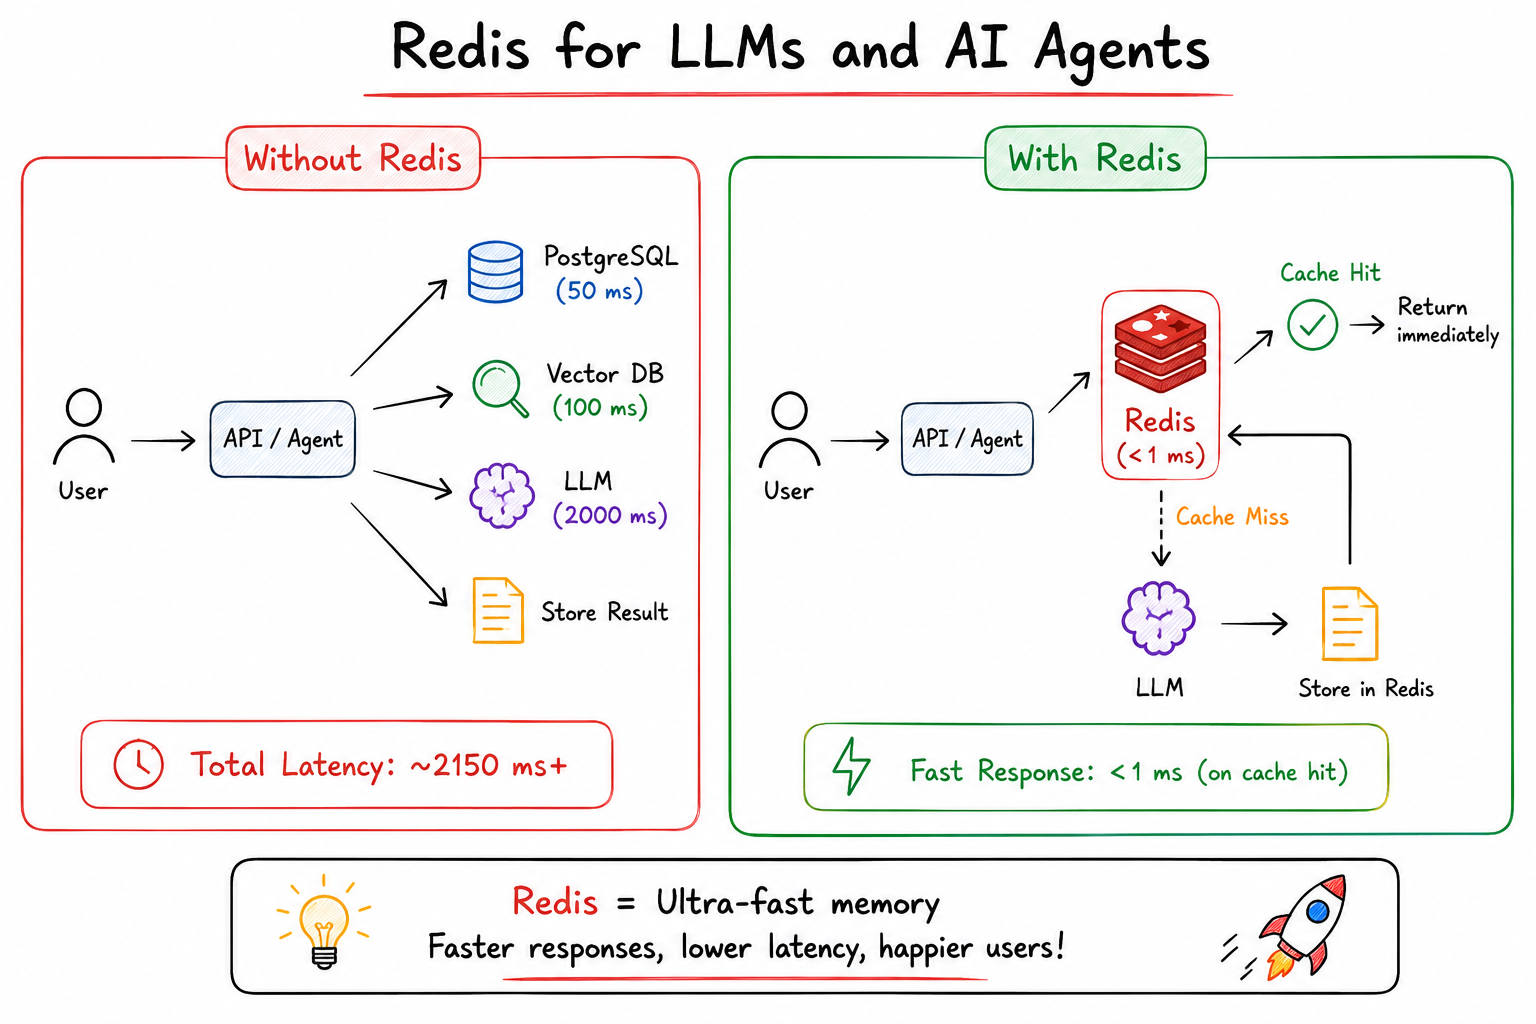

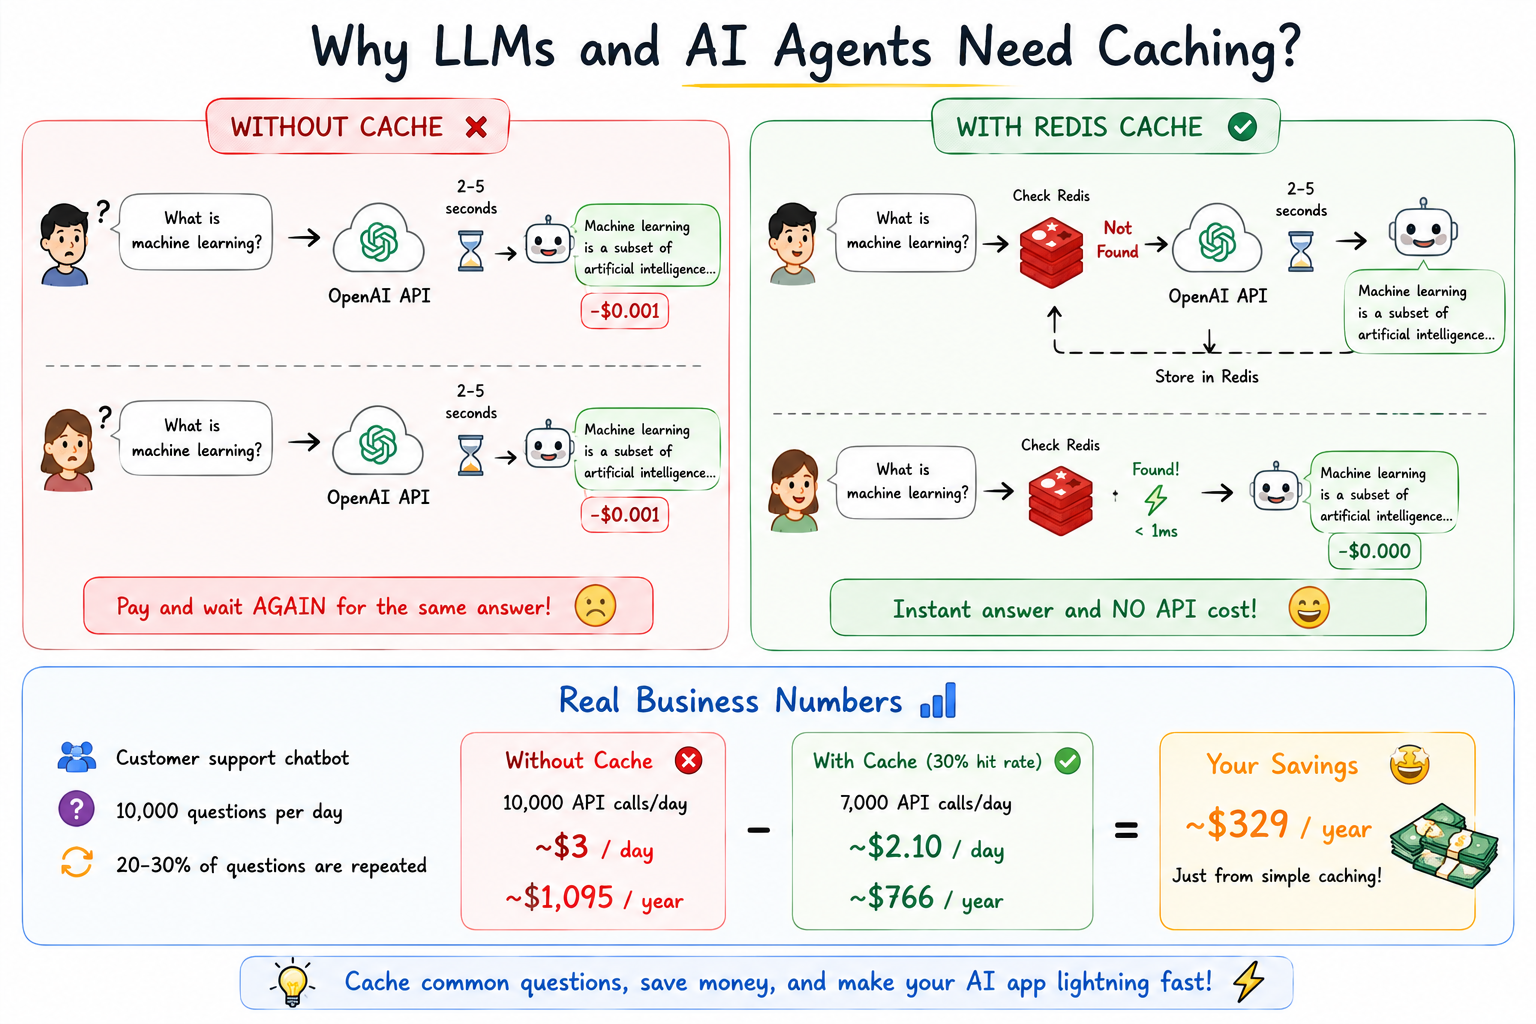


### Why AI Agents Specifically Need Caching:

1. **Conversation History** — An agent must remember what was said earlier in the chat
2. **Tool Results** — If an agent already looked up today's weather, cache it for 10 minutes
3. **Embeddings** — Computing vector embeddings is slow and expensive; cache them indefinitely
4. **Rate Limiting** — Prevent users from hammering your API endpoints
5. **RAG Document Cache** — Cache retrieved document chunks to avoid re-fetching

---

## 3. Setting Up Redis with Docker Desktop (Windows)

We use **Redis Stack** — the full-featured version that includes vector search, which we need for Module 3 and 6.

### Step 1: Make sure Docker Desktop is running
Look for the Docker whale icon in your Windows system tray (bottom right). If it's not there, open Docker Desktop from the Start menu and wait for it to fully start.

### Step 2: Start Redis
Open a terminal (PowerShell or Command Prompt) **in this project folder** and run:

```bash
docker-compose up -d
```

The `-d` flag means "run in the background" (detached mode).

First time: Docker will download the Redis Stack image (~200MB). Subsequent starts are instant.

### Step 3: Verify Redis is running
```bash
docker ps
```
You should see a container named `redis-ai-course` in the list.

### What Gets Started:
- **Port 6379** — Redis itself (our Python code connects here)
- **Port 8001** — RedisInsight, a visual browser-based UI to see your data

Open **http://localhost:8001** in your browser to see the RedisInsight dashboard.

### Stopping Redis when done:
```bash
docker-compose down
```

---

In [ ]:
# Install all packages needed for this course
# Run this cell once when you first start
%pip install redis openai groq python-dotenv numpy gradio tiktoken -q
print("All packages installed!")

Note: you may need to restart the kernel to use updated packages.
All packages installed!



[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import redis
import os
from dotenv import load_dotenv

# Load API keys from .env file
# Copy .env.example to .env and fill in your keys
load_dotenv()

# Connect to Redis
# decode_responses=True means Redis returns Python strings instead of bytes
r = redis.Redis(
    host=os.getenv('REDIS_HOST', 'localhost'),
    port=int(os.getenv('REDIS_PORT', 6379)),
    decode_responses=True
)

# Test the connection with a PING
try:
    response = r.ping()
    info = r.info()
    print(f"Connected to Redis!")
    print(f"  Redis version : {info['redis_version']}")
    print(f"  Memory used   : {info['used_memory_human']}")
    print(f"  Keys stored   : {r.dbsize()}")
except redis.ConnectionError as e:
    print(f"Could not connect to Redis: {e}")
    print("  Make sure Docker Desktop is running and you ran: docker-compose up -d")

Connected to Redis!
  Redis version : 7.4.7
  Memory used   : 1.32M
  Keys stored   : 2


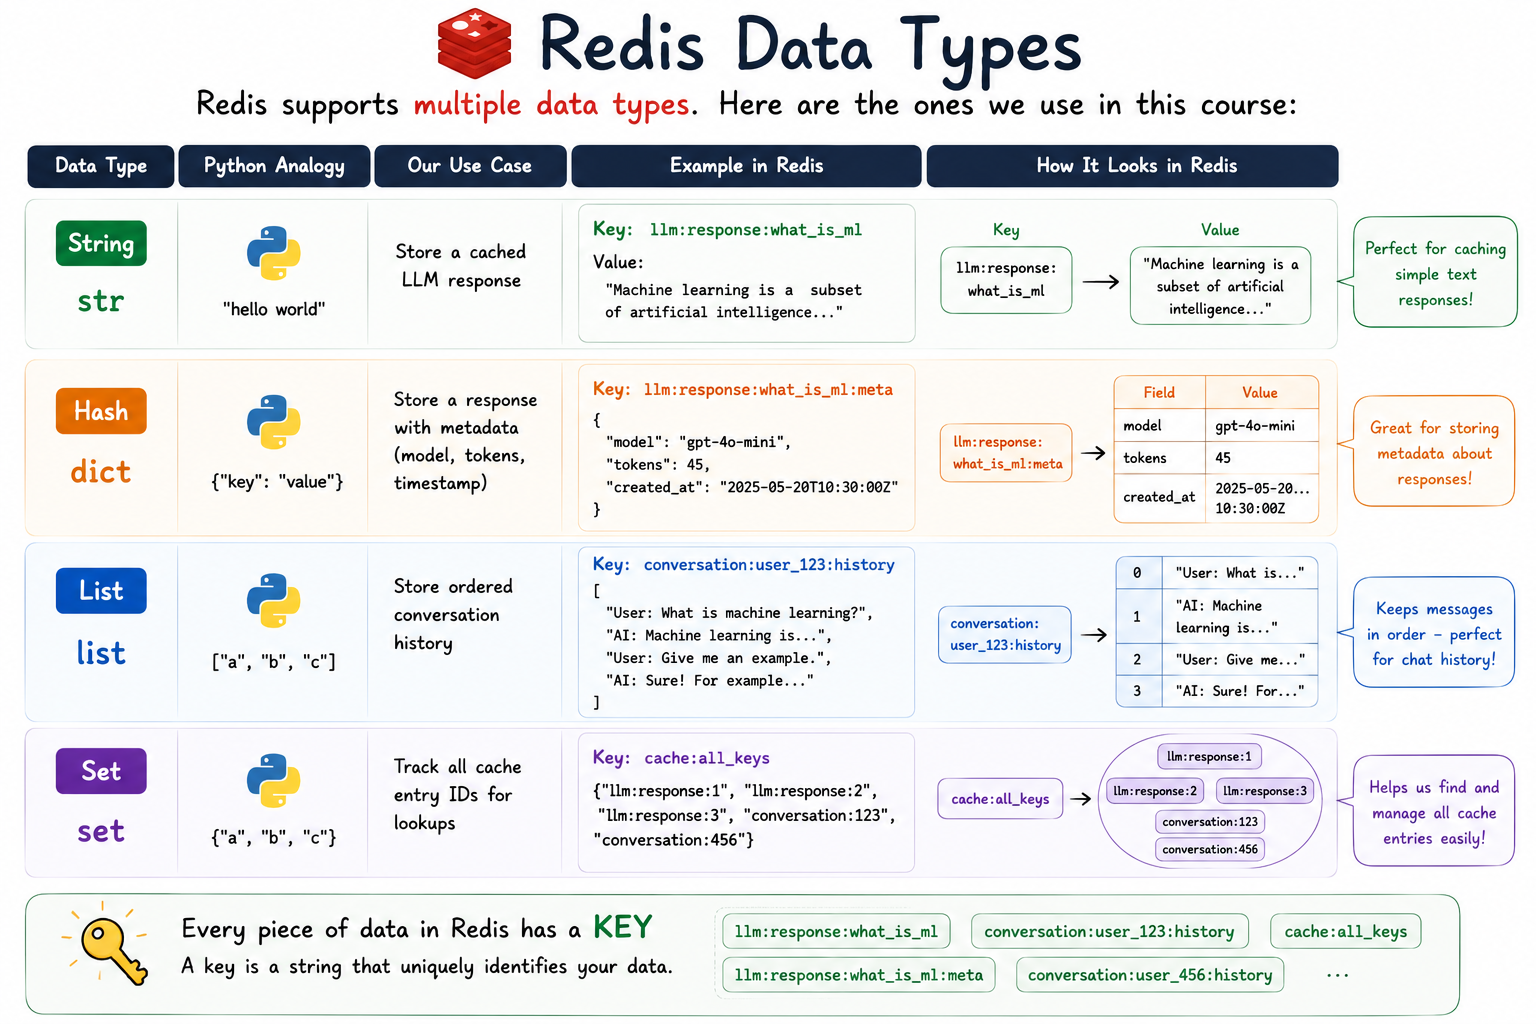

In [2]:
# ─────────────────────────────────────────────
# STRINGS — The most basic Redis data type
# Use for: single values, cached responses
# ─────────────────────────────────────────────

print("=" * 45)
print("REDIS STRINGS")
print("=" * 45)

# SET stores any string value under a key
r.set("course:name", "Redis for AI Caching")
r.set("course:module", "1")

# GET retrieves a value by key
name = r.get("course:name")
module = r.get("course:module")
print(f"course:name   -> {name}")
print(f"course:module -> {module}")

# EXISTS checks if a key is present (returns 1 or 0)
print(f"\nDoes 'course:name' exist? {bool(r.exists('course:name'))}")
print(f"Does 'fake:key' exist?   {bool(r.exists('fake:key'))}")



REDIS STRINGS
course:name   -> Redis for AI Caching
course:module -> 1

Does 'course:name' exist? True
Does 'fake:key' exist?   False


In [3]:
# DEL removes a key
r.delete("course:name", "course:module")
print(f"\nAfter deletion, 'course:name' exists? {bool(r.exists('course:name'))}")


After deletion, 'course:name' exists? False


### TTL = Time To Live

In [4]:
import time

r.set("demo:expiring", "I will disappear!", ex=10)

print(f"Key stored! TTL = {r.ttl('demo:expiring')} seconds")
print(f"GO CHECK REDIS DASHBOARD NOW — you will see 'demo:expiring'")
print("\nWaiting 10 seconds...")
time.sleep(10)

print(f"\nValue now: {r.get('demo:expiring')}")
print("REFRESH DASHBOARD — key is gone!")


Key stored! TTL = 10 seconds
GO CHECK REDIS DASHBOARD NOW — you will see 'demo:expiring'

Waiting 10 seconds...

Value now: None
REFRESH DASHBOARD — key is gone!


In [5]:
import json

# ─────────────────────────────────────────────
# HASHES — Store structured data (like a dict)
# Use for: caching a response WITH its metadata
# ─────────────────────────────────────────────

print("=" * 45)
print("REDIS HASHES")
print("=" * 45)

# HSET stores multiple fields under one key
r.hset("llm:response:sample", mapping={
    "prompt": "What is machine learning?",
    "response": "Machine learning is a branch of AI where systems learn from data to make predictions or decisions without being explicitly programmed for each task.",
    "model": "gpt-4o-mini",
    "tokens": "52",
    "cost_usd": "0.000008"
})
print("Stored hash with 5 fields under key: llm:response:sample")

# HGET retrieves one specific field
response_text = r.hget("llm:response:sample", "response")
print(f"\nJust the response field:")
print(f"  {response_text}")

# HGETALL retrieves all fields as a Python dict
all_fields = r.hgetall("llm:response:sample")
print(f"\nAll fields:")
for field, value in all_fields.items():
    display = value if len(value) <= 60 else value[:60] + "..."
    print(f"  {field:12} : {display}")

# r.delete("llm:response:sample")

REDIS HASHES
Stored hash with 5 fields under key: llm:response:sample

Just the response field:
  Machine learning is a branch of AI where systems learn from data to make predictions or decisions without being explicitly programmed for each task.

All fields:
  model        : gpt-4o-mini
  prompt       : What is machine learning?
  cost_usd     : 0.000008
  response     : Machine learning is a branch of AI where systems learn from ...
  tokens       : 52


In [6]:
# ─────────────────────────────────────────────
# LISTS — Ordered sequences
# Use for: conversation history (ordered messages)
# ─────────────────────────────────────────────

print("=" * 45)
print("REDIS LISTS")
print("=" * 45)

# Each message is stored as a JSON string
conversation = [
    {"role": "system", "content": "You are a helpful AI assistant."},
    {"role": "user", "content": "Hi! What is Redis?"},
    {"role": "assistant", "content": "Redis is an in-memory data store used for caching."},
    {"role": "user", "content": "Why is it fast?"},
    {"role": "assistant", "content": "Because it stores everything in RAM, not on disk."},
]

# RPUSH adds items to the RIGHT (end) of the list — preserves order
for msg in conversation:
    r.rpush("demo:conversation", json.dumps(msg))

print(f"Pushed {len(conversation)} messages to 'demo:conversation'")
print(f"List length: {r.llen('demo:conversation')} messages")

# LRANGE retrieves items by index (0, -1 means everything)
raw_messages = r.lrange("demo:conversation", 0, -1)
parsed = [json.loads(m) for m in raw_messages]

print("\nFull conversation history:")
for msg in parsed:
    print(f"  [{msg['role'].upper():10}] {msg['content']}")

# LTRIM keeps only a slice of the list
# This is how we implement a "sliding window" memory — keep last N messages
r.ltrim("demo:conversation", -3, -1)  # Keep only the last 3 messages
trimmed = [json.loads(m) for m in r.lrange("demo:conversation", 0, -1)]
print(f"\nAfter LTRIM (keep last 3): {len(trimmed)} messages")
for msg in trimmed:
    print(f"  [{msg['role'].upper():10}] {msg['content']}")

# r.delete("demo:conversation")

REDIS LISTS
Pushed 5 messages to 'demo:conversation'
List length: 5 messages

Full conversation history:
  [SYSTEM    ] You are a helpful AI assistant.
  [USER      ] Hi! What is Redis?
  [ASSISTANT ] Redis is an in-memory data store used for caching.
  [USER      ] Why is it fast?
  [ASSISTANT ] Because it stores everything in RAM, not on disk.

After LTRIM (keep last 3): 3 messages
  [ASSISTANT ] Redis is an in-memory data store used for caching.
  [USER      ] Why is it fast?
  [ASSISTANT ] Because it stores everything in RAM, not on disk.
